# Analysing PBMCs with bixverse

*Python port of the R vignette [Analysing PBMCs with bixverse](https://gregorlueg.github.io/bixverse/articles/pbmc_single_cell.html). Original authors: Grant Neilson, Gregor Lueg and Liesbeth François.*

A standard single cell analysis on the PBMC3k data set with `bixverse`. If you
have not read the [design choices](design_single_cell.ipynb) and the
[introductory vignette](thinking_single_cell.ipynb), do so first; this one
assumes you know how the `SingleCells` class, the on-disk storage and the
cells-to-keep logic work.

In [1]:
import tempfile
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed
from bixverse.params import NeighboursParams

## Loading the data

We download the PBMC3k data and load it through the Cell Ranger style MTX
reader. The experiment lives in a directory: the cell- and gene-major binary
stores plus a DuckDB with obs and var.

In [2]:
pbmc3k_path = bv.io.download_pbmc3k()

tempdir_pbmc = tempfile.TemporaryDirectory()

sc = bv.io.load_mtx(
    Path(tempdir_pbmc.name) / "pbmc3k",
    bv.io.get_cell_ranger_params(pbmc3k_path),
    verbose=True,
)

sc

Text pass (real): 1 buckets, ~2700 cells/bucket
Text pass done: 28.10ms (cell-major order)
Genes passing QC: 11_139 / 32_738
Cells passing QC: 2_700 / 2_700
Writing pass: 1 buckets, no sort
  Wrote bucket 1/1 (100%)
Writing pass done: 38.20ms
Converting the cell-based data into the gene-based format.


  Counted 2_269_399 non-zeros over 11_139 genes in 1.37ms; converting in 1 phase(s).
  Phase 1/1: genes 0-11139, scatter 5.08ms, compress + write 43.15ms
  Conversion into gene-friendly format done: 54.97ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmp3dm_1i0x/pbmc3k',
  cells=2700 (kept 2700), genes=11139,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

A quick look at the var table. The column names from the MTX files are not
always informative, so we rename the gene symbol column to something sensible
and set up mappings between Ensembl IDs and symbols.

In [3]:
sc.var().head()

gene_idx,gene_id,column1,no_cells_exp
u32,str,str,i32
0,"""ENSG00000225880""","""LINC00115""",18
1,"""ENSG00000188976""","""NOC2L""",258
2,"""ENSG00000188290""","""HES4""",145
3,"""ENSG00000187608""","""ISG15""",1206
4,"""ENSG00000131591""","""C1orf159""",24


In [4]:
sc.rename_var_col("column1", "gene_symbol")

var = sc.var()

ensembl_to_symbol = dict(zip(var["gene_id"], var["gene_symbol"], strict=True))
symbol_to_ensembl = dict(zip(var["gene_symbol"], var["gene_id"], strict=True))

## Quality control

### Gene set proportions

First up, the proportion of counts that map to mitochondrial and ribosomal
genes per cell. They land directly in the obs table in the DuckDB.

In [5]:
gs_of_interest = {
    "MT": var.filter(pl.col("gene_symbol").str.contains("^MT-"))["gene_id"].to_list(),
    "Ribo": var.filter(pl.col("gene_symbol").str.contains("^RP[SL]"))[
        "gene_id"
    ].to_list(),
}

bv.qc.gene_set_proportions(sc, gs_of_interest, streaming=False, verbose=True)

sc.obs().head()

Load in data: 2.50ms
Finished the gene set proportion calculations: 796.38µs


cell_idx,cell_id,nnz,lib_size,to_keep,MT,Ribo
u32,str,f64,f64,bool,f64,f64
0,"""AAACATACAACCAC-1""",778.0,2418.0,true,0.03019,0.437138
1,"""AAACATTGAGCTAC-1""",1346.0,4896.0,true,0.03799,0.424632
2,"""AAACATTGATCAGC-1""",1126.0,3144.0,true,0.008906,0.317112
3,"""AAACCGTGCTTCCG-1""",953.0,2632.0,true,0.017477,0.243161
4,"""AAACCGTGTATGCG-1""",520.0,979.0,true,0.012257,0.149132


MT and Ribo are now columns in obs.

### MAD outlier detection

Per-cell QC metrics and MAD-based outlier detection flag the problematic
cells. `run_cell_qc` returns a `CellQc` that carries the metrics, the
per-metric outlier calls and a combined outlier vector.

In [6]:
qc_df = sc.obs(cols=["cell_id", "lib_size", "nnz", "MT"])

metrics = {
    "log10_lib_size": np.log10(qc_df["lib_size"].to_numpy()),
    "log10_nnz": np.log10(qc_df["nnz"].to_numpy()),
    "MT": qc_df["MT"].to_numpy(),
}

directions: dict[str, Literal["twosided", "below", "above"]] = {
    "log10_lib_size": "twosided",
    "log10_nnz": "twosided",
    "MT": "above",
}

qc = bv.qc.run_cell_qc(
    metrics,
    sc.cells_to_keep,
    directions=directions,
    threshold=3.0,
)

print(f"{qc.combined.sum()} of {qc.combined.size} cells flagged")

qc.thresholds

210 of 2700 cells flagged


metric,group,median,upper_threshold,lower_threshold
str,str,f64,f64,f64
"""log10_lib_size""","""all""",3.341138,3.77857,2.903706
"""log10_nnz""","""all""",2.909021,3.217482,2.60056
"""MT""","""all""",0.020346,0.044474,null


`CellQc` comes with two plots. `violin_plot` draws one violin per metric with
the outliers highlighted:

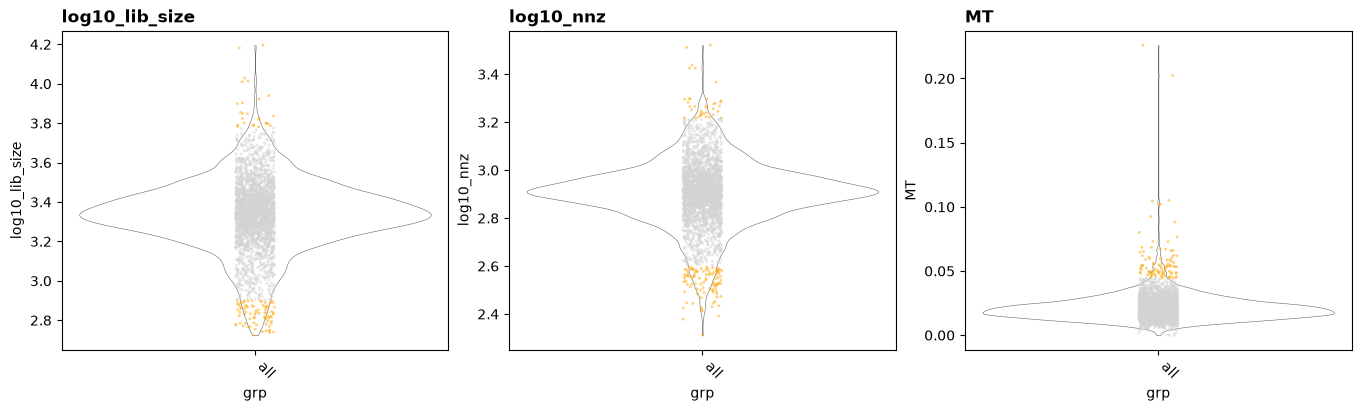

In [7]:
bv.pl.violin_plot(qc)
plt.show()

and `joint_plot` compares the genes against the UMIs per cell.

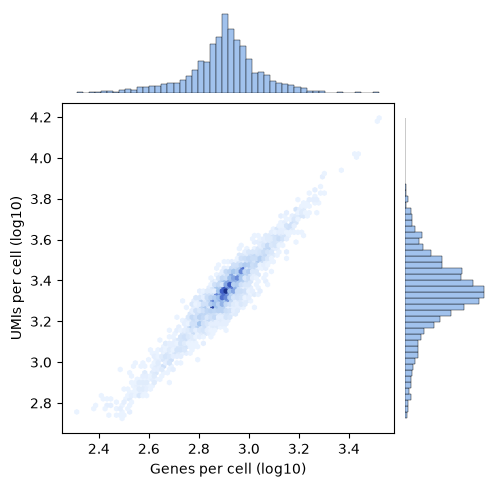

In [8]:
bv.pl.joint_plot(qc)
plt.show()

### Filtering cells

We store the outlier flag in obs and then set the cells to keep. From here
on every downstream method (HVG selection, PCA, ...) only sees the retained
cells.

In [9]:
sc.add_obs(pl.DataFrame({"cell_idx": qc.cell_idx, "outlier": qc.combined}))

sc.set_cells_to_keep(qc.cell_idx[~qc.combined])

sc

SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmp3dm_1i0x/pbmc3k',
  cells=2700 (kept 2490), genes=11139,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

## Feature selection, PCA and neighbours

With QC done, the standard pipeline: highly variable genes, PCA and the
nearest neighbours.

In [10]:
bv.pp.find_hvg(sc, hvg_no=2000, verbose=True)

bv.pp.calculate_pca(sc, no_pcs=30, sparse_svd=True)

# the data is so tiny that an exhaustive kNN search is faster than building an
# approximate nearest neighbour index
bv.graph.find_neighbours(
    sc, neighbours_params=NeighboursParams(knn_method="exhaustive")
)

HVG (VST): 11_139 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 3.70ms
HVG (VST): Fitted Loess in 481.71µs
HVG (VST): Standardised variance in 1.03ms (1_174 gene(s) re-read for the clip)
HVG (VST): Total run time -> 5.25ms
Using sparse SVD solving on scaled data on 2000 HVG.


Sparse PCA: Loaded in data in 6.89ms
Sparse PCA: finished the data preparations in 1.11ms


Sparse PCA: finished calculations in 169.71ms
Sparse PCA: total run time -> 177.76ms
Generating kNN data with exhaustive method.


Building Exhaustive index ...
... built Exhaustive index in 123.50µs
Generated Exhaustive index: 128.17µs
Querying Exhaustive index (self) ...
... queried Exhaustive index (self) in 3.82ms
Queried Exhaustive index: 3.85ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 8.51ms


## Clustering and marker detection

### Leiden clustering

Leiden clustering, then differential expression across all clusters. Louvain
is there too if you want it, but Leiden has the better properties, see
[Traag et al.](https://www.nature.com/articles/s41598-019-41695-z).

In [11]:
bv.graph.find_clusters(sc, res=1.0, name="leiden_clusters")

all_markers = bv.de.find_all_markers(sc, "leiden_clusters").with_columns(
    pl.col("gene_id").replace_strict(ensembl_to_symbol).alias("gene_symbol")
)

all_markers.filter(pl.col("fdr") <= 0.05).sort(
    pl.col("lfc").abs(), descending=True
).head()

  Progress: 17% (2_000 / 11_139 genes, 2.86ms)
  Progress: 26% (3_000 / 11_139 genes, 4.07ms)
  Progress: 35% (4_000 / 11_139 genes, 5.41ms)
  Progress: 44% (5_000 / 11_139 genes, 6.65ms)
  Progress: 53% (6_000 / 11_139 genes, 7.90ms)
  Progress: 62% (7_000 / 11_139 genes, 9.82ms)
  Progress: 71% (8_000 / 11_139 genes, 11.16ms)
  Progress: 80% (9_000 / 11_139 genes, 12.48ms)
  Progress: 98% (11_000 / 11_139 genes, 15.43ms)
  Progress: 100% (11_139 / 11_139 genes, 15.97ms)
One-vs-rest across 8 groups: 20.28ms


grp,gene_id,lfc,prop1,prop2,z_scores,p_values,fdr,gene_symbol
i32,str,f64,f64,f64,f64,f64,f64,str
2,"""ENSG00000163220""",4.083154,0.995575,0.215407,38.091501,8.8571e-318,1.3321e-314,"""S100A9"""
5,"""ENSG00000105374""",4.068351,1.0,0.255993,24.941065,1.3347e-137,4.7629e-135,"""NKG7"""
5,"""ENSG00000115523""",3.972615,0.941558,0.133134,28.530808,2.4304e-179,2.2549e-176,"""GNLY"""
2,"""ENSG00000090382""",3.946784,0.997788,0.520608,33.789401,1.4113e-250,7.0753e-248,"""LYZ"""
2,"""ENSG00000143546""",3.623994,0.973451,0.122669,40.523577,0.0,0.0,"""S100A8"""


### Fast clustering

For large data sets there is an accelerated clustering: k-means first
(`floor(4 * sqrt(N))` centroids by default), then Louvain or Leiden on a graph over the
centroids, across a set of resolutions. The centroid graph options, the seed
stability statistics and how the result compares against the full graph
clustering are in the
[clustering and annotation vignette](cell_type_annotation.ipynb).

In [12]:
fast_cluster_res = bv.graph.fast_cluster(
    sc,
    resolutions=(2.0, 1.0, 0.5),
    # also return the k-means clustering
    return_kmeans=True,
)

fast_cluster_res.memberships.head()

 k-means with 199 centroids: 17.09ms
Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 461.17µs
 Centroid graph: 1.01ms
 Community detection: 1.08ms


cell_idx,res_2,res_1,res_0.5
u32,i32,i32,i32
0,2,0,0
1,3,3,3
2,2,0,0
3,0,1,1
4,1,2,2


The k-means memberships and centroids sit on the result.

In [13]:
centroids = fast_cluster_res.centroids
assert centroids is not None
kmeans_membership = fast_cluster_res.k_means_cluster

centroids.shape

(199, 30)

The memberships carry `cell_idx`, so they go straight into obs.

In [14]:
sc.add_obs(fast_cluster_res.memberships)

sc.obs(filtered=True).head()

cell_idx,cell_id,nnz,lib_size,to_keep,MT,Ribo,outlier,leiden_clusters,res_2,res_1,res_0.5
u32,str,f64,f64,bool,f64,f64,bool,i32,i32,i32,i32
0,"""AAACATACAACCAC-1""",778.0,2418.0,true,0.03019,0.437138,false,0,2,0,0
1,"""AAACATTGAGCTAC-1""",1346.0,4896.0,true,0.03799,0.424632,false,3,3,3,3
2,"""AAACATTGATCAGC-1""",1126.0,3144.0,true,0.008906,0.317112,false,0,2,0,0
3,"""AAACCGTGCTTCCG-1""",953.0,2632.0,true,0.017477,0.243161,false,2,0,1,1
4,"""AAACCGTGTATGCG-1""",520.0,979.0,true,0.012257,0.149132,false,5,1,2,2


### Dimensionality reduction

UMAP and t-SNE, both from
[manifolds-rs](https://github.com/GregorLueg/manifolds-rs) (the `embed`
extra).

In [15]:
bv.embed.umap(sc)

# perplexity 10 is the default; `bv.embed.tsne_defaults()` has the rest
bv.embed.tsne(sc)

`bv.pl` (the `plots` extra) has the basic plots. `embedding_plot` shows an
embedding coloured by an obs column:

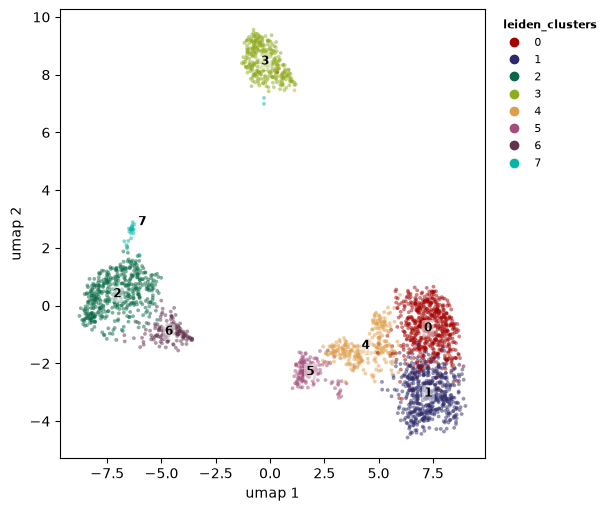

In [16]:
bv.pl.embedding_plot(
    sc,
    "umap",
    "leiden_clusters",
    label_by="leiden_clusters",
    discrete=True,
)
plt.show()

Same again for the t-SNE:

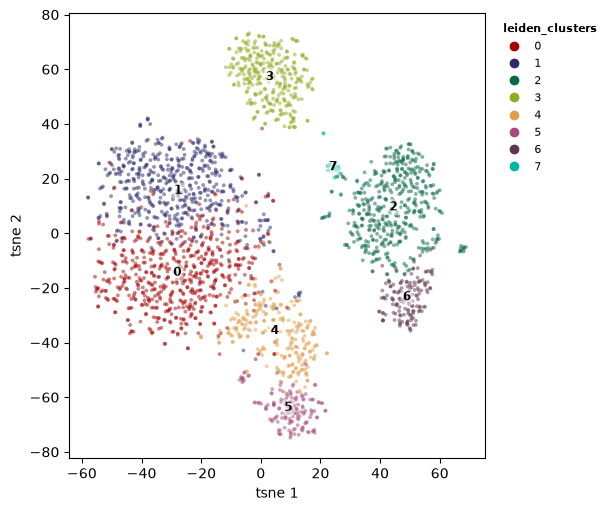

In [17]:
bv.pl.embedding_plot(
    sc,
    "tsne",
    "leiden_clusters",
    label_by="leiden_clusters",
    discrete=True,
)
plt.show()

And `feature_plot` puts the expression of a gene on the embedding:

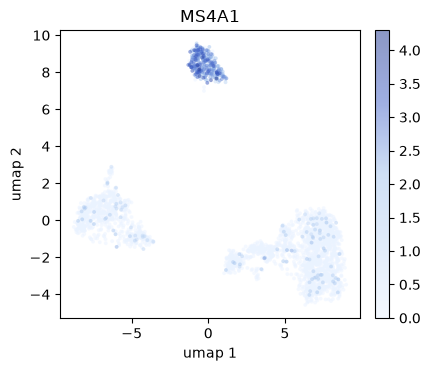

In [18]:
bv.pl.feature_plot(
    sc,
    ["ENSG00000156738"],
    "umap",
    feature_labels={"ENSG00000156738": "MS4A1"},
)
plt.show()

### Cell type annotation

A set of marker genes for the annotation:

In [19]:
cell_markers = {
    "CD3D": "T cells",
    "CD3E": "T cells",
    "CD3G": "T cells",
    "IL7R": "CD4+ T",
    "CD4": "CD4+ T",
    "CD8A": "CD8+ T",
    "CD8B": "CD8+ T",
    "MS4A1": "B cells",
    "CD79A": "B cells",
    "CD19": "B cells",
    "CD14": "CD14+ Mono",
    "LYZ": "CD14+ Mono",
    "S100A8": "CD14+ Mono",
    "FCGR3A": "CD16+ Mono",
    "CDKN1C": "CD16+ Mono",
    "GNLY": "NK",
    "NKG7": "NK",
    "NCAM1": "NK",
    "FCER1A": "mDC",
    "CD1C": "mDC",
    "LILRA4": "pDC",
    "CLEC4C": "pDC",
    "PPBP": "Platelet",
    "PF4": "Platelet",
}

We annotate the PBMCs with scType from
[Ianevski et al. (2022)](https://doi.org/10.1038/s41467-022-28803-w).
`prepare_cell_markers` gets the markers into shape, `calc_sc_type_scores`
scores every cell and `score_clusters` summarises the scores per cluster into
a cell type call.

In [20]:
cell_markers_df = pl.DataFrame(
    {"gene_symbol": list(cell_markers), "cell_type": list(cell_markers.values())}
).join(var.select("gene_symbol", "gene_id"), on="gene_symbol")

marker_list = bv.annotate.prepare_cell_markers(sc, cell_markers_df)

sctype_scores = bv.annotate.calc_sc_type_scores(sc, marker_list)

leiden = sc.obs(cols=["leiden_clusters"], filtered=True)["leiden_clusters"]

cell_type_anno = bv.annotate.score_clusters(sctype_scores, leiden.to_numpy())

cell_type_anno

ScType: 10 cell types, 23 marker genes, 2490 cells
ScType: streamed scoring in 646.50µs
ScType: total run time -> 905.83µs


cluster_id,cell_type,scores,n_cells
i32,str,f64,i32
0,"""T cells""",561.10437,585
1,"""T cells""",442.369629,545
2,"""CD14+ Mono""",1336.154541,452
3,"""B cells""",1009.238892,314
4,"""CD8+ T""",394.16748,269
5,"""NK""",543.234985,154
6,"""CD16+ Mono""",503.897217,147
7,"""mDC""",164.724411,24


Back into obs it goes.

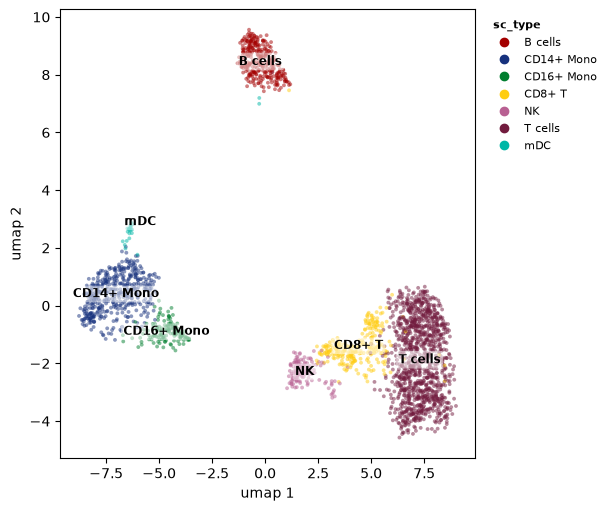

In [21]:
sc.add_obs(
    sc.obs(cols=["cell_idx", "leiden_clusters"], filtered=True)
    .join(
        cell_type_anno.select(
            pl.col("cluster_id").alias("leiden_clusters"),
            pl.col("cell_type").alias("sc_type"),
        ),
        on="leiden_clusters",
        how="left",
    )
    .select("cell_idx", "sc_type")
)

bv.pl.embedding_plot(
    sc,
    "umap",
    "sc_type",
    label_by="sc_type",
    discrete=True,
)
plt.show()

The marker expression per cluster as a dot plot with `dot_plot`:

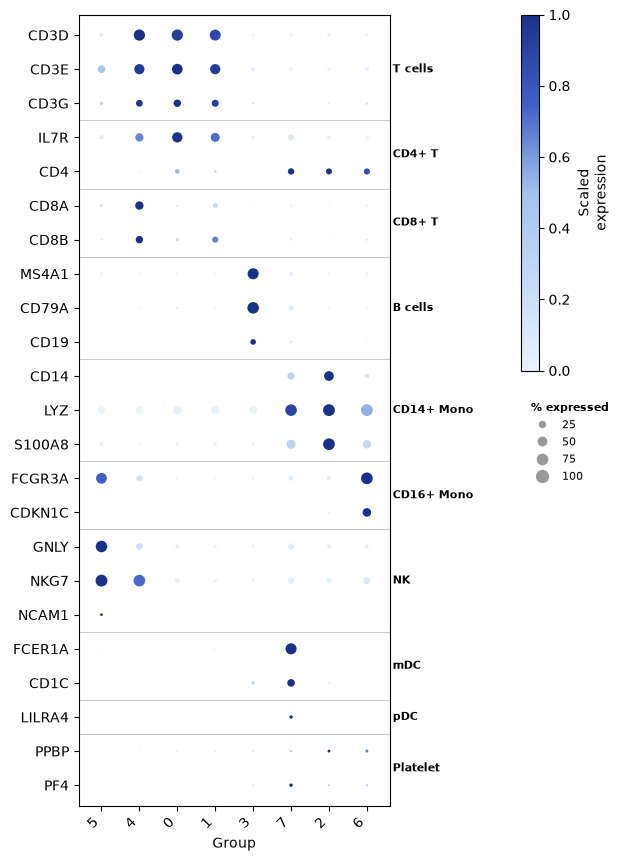

In [22]:
features_vec = [symbol_to_ensembl[s] for s in cell_markers if s in symbol_to_ensembl]

bv.pl.dot_plot(
    sc,
    features_vec,
    "leiden_clusters",
    feature_labels={f: ensembl_to_symbol[f] for f in features_vec},
    # keyed by the display label, here the symbol
    feature_grouping=cell_markers,
    scale_exp=True,
    cluster_groups=True,
)
plt.show()

### Per-cell gene expression

Next to the feature plot, a stacked violin plot shows the expression per
cluster.

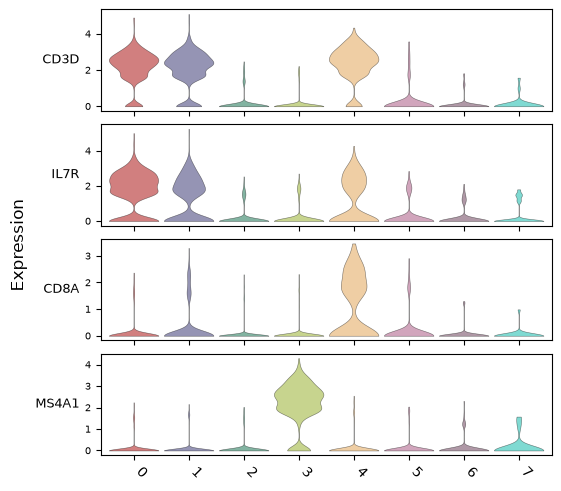

In [23]:
features = [symbol_to_ensembl[s] for s in ("CD3D", "IL7R", "CD8A", "MS4A1")]

bv.pl.stacked_violin_plot(
    sc,
    features,
    "leiden_clusters",
    feature_labels={f: ensembl_to_symbol[f] for f in features},
)
plt.show()

## Clean up

In [24]:
tempdir_pbmc.cleanup()